# CIS 3400 — Week 7 Partner Data Investigation
## Philadelphia 311 Service & Information Requests

### Team Information
**Partner 1:** Timothy White  
**Partner 2:** Alan  

**Class:** CIS 3400 Advanced Programming  
**Due:** Sunday, October 4, 2026

---

## Your Role

You and your partner are **junior data analysts supporting a city management team**.

Philadelphia receives non-emergency service and information requests through Philly311. Your job is to use Python to investigate the 2025 data, identify meaningful patterns, and communicate what you discover to a nontechnical managerial audience.

### Your final work should answer:

> **What can this data tell city managers that would help them better understand city service requests?**

You will choose your own specific managerial question.

### Use Monday's notebook as your guide

Follow the same general process:

**Question → Inspect → Clean → Transform → Aggregate → Visualize → Interpret → Communicate**

This starter notebook gives you the structure. **You and your partner must decide what analysis belongs in it.**

AI/VIBE coding is allowed for coding assistance, debugging, explanations, and visualization ideas. However, **both partners are responsible for understanding the code and verifying the results.**


# 1. Import the Python Libraries

We will start with **pandas** for working with data and **matplotlib** for visualization.

You may import additional libraries later if your analysis requires them.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)


# 2. Load the Philadelphia 311 Data

Upload the CSV file provided in Blackboard to Colab, or place it in the same folder as this notebook if you are using VS Code/Jupyter.

If your instructor gives the file a different name, change `FILE` below.


In [ ]:
FILE = "public_cases_fc.csv"

df = pd.read_csv(FILE)

print("Data loaded successfully!")
print("Rows, columns:", df.shape)


Data loaded successfully!
Rows, columns: (518841, 20)


# 3. Define Your Managerial Question

**Do this BEFORE you begin serious analysis.**

Your question should be something a city manager or department leader might actually care about.

It should require analysis — not simply looking up one number.

### Primary Managerial Question

**Our question:**  
Which city services generate the most resident complaints, and why?

### Supporting Questions

1. Who is complaining younger or older  
2. What is the benefactor
3.  What can help fix the service for better

You may revise these questions as you learn more about the data.


# 4. Understand the Data

Before analyzing anything, find out what you actually have.

Use Monday's notebook as a guide.

Consider:

- How many rows and columns are there?
- What does one row represent?
- What columns are available?
- What data types are being used?
- Which columns might help answer your managerial question?
- Are any column names or values confusing?


In [ ]:
# Begin exploring your DataFrame here.
display(df[df["service_type"] == "Abandoned Vehicle"].head())

,objectid,service_request_id,status,status_notes,service_name,service_code,agency_responsible,service_notice,requested_datetime,updated_datetime,expected_datetime,address,zipcode,media_url,lat,lon,subject,closed_datetime,gdb_geomattr_data,service_type
14,5056966,17346539,Closed,Information Provided,Abandoned Vehicle,SR-PD01,Police Department,120 Business Days,2025-01-01 00:30:05+00,2025-02-13 14:57:42+00,2025-07-08 00:00:00+00,3408 RHAWN ST,19136.0,NaN,40.043826,-75.030424,NaN,2025-02-13 14:57:38+00,NaN,Abandoned Vehicle
44,5056996,17346589,Closed,Information Provided,Abandoned Vehicle,SR-PD01,Police Department,120 Business Days,2025-01-01 08:11:42+00,2025-02-19 16:27:44+00,2025-07-10 00:00:00+00,1300 DEVEREAUX AVE,19111.0,https://d17aqltn7cihbm.cloudfront.net/uploads/...,40.037560,-75.081253,NaN,2025-02-19 16:27:37+00,NaN,Abandoned Vehicle
52,5057004,17346602,Open,NaN,Abandoned Vehicle,SR-PD01,Police Department,120 Business Days,2025-01-01 12:33:11+00,2025-01-02 14:40:26+00,2025-07-10 00:00:00+00,3648 SEARS ST,19146.0,https://d17aqltn7cihbm.cloudfront.net/uploads/...,39.938740,-75.203195,NaN,NaN,NaN,Abandoned Vehicle
65,5057017,17346627,Closed,Information Provided,Abandoned Vehicle,SR-PD01,Police Department,120 Business Days,2025-01-01 14:31:27+00,2025-06-11 20:18:50+00,2025-07-10 00:00:00+00,27 S 51ST ST,19139.0,NaN,39.958723,-75.223003,NaN,2025-06-11 20:18:44+00,NaN,Abandoned Vehicle
71,5057023,17346653,Closed,Information Provided,Abandoned Vehicle,SR-PD01,Police Department,120 Business Days,2025-01-01 15:31:33+00,2025-07-24 20:15:16+00,2025-07-10 00:00:00+00,1200 GRANT AVE,19115.0,https://d17aqltn7cihbm.cloudfront.net/uploads/...,40.088261,-75.048249,NaN,2025-07-24 20:15:09+00,NaN,Abandoned Vehicle


In [ ]:
# Where complaints genereate from by zip
existing_columns = df.columns.tolist()
print("Columns in dataset:", existing_columns)

# Check if we have any zipcode data to approximate geographic/neighborhood demographics
if 'zipcode' in df.columns:
    print("\n=== Top Zip Codes Complaining  ===")
    display(df['zipcode'].value_counts().head(10))
else:
    print("\nNo zipcode or demographic columns exist in this dataset.")

Columns in dataset: ['objectid', 'service_request_id', 'status', 'status_notes', 'service_name', 'service_code', 'agency_responsible', 'service_notice', 'requested_datetime', 'updated_datetime', 'expected_datetime', 'address', 'zipcode', 'media_url', 'lat', 'lon', 'subject', 'closed_datetime', 'gdb_geomattr_data', 'service_type']

=== Top Zip Codes Complaining  ===


,count
zipcode,
19143.0,11912
19134.0,11185
19140.0,9698
19146.0,9531
19124.0,8977
19139.0,8523
19147.0,8493
19148.0,8251
19120.0,8170


In [ ]:
# Comprehensive inspection of the dataset
print("=== Dataset Dimensions ===")
print(f"Rows: {df.shape[0]:,}, Columns: {df.shape[1]}\n")

print("=== Column Names and Data Types ===")
display(df.info())

print("\n=== Summary Statistics (Numerical Columns) ===")
display(df.describe(include='all'))

print("\n=== Missing Values Count (Top Columns) ===")
missing_counts = df.isnull().sum()
display(missing_counts[missing_counts > 0].sort_values(ascending=False))

=== Dataset Dimensions ===
Rows: 518,841, Columns: 20

=== Column Names and Data Types ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 518841 entries, 0 to 518840
Data columns (total 20 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   objectid            518841 non-null  int64  
 1   service_request_id  518841 non-null  int64  
 2   status              518841 non-null  object 
 3   status_notes        312128 non-null  object 
 4   service_name        518841 non-null  object 
 5   service_code        449681 non-null  object 
 6   agency_responsible  518841 non-null  object 
 7   service_notice      231509 non-null  object 
 8   requested_datetime  518841 non-null  object 
 9   updated_datetime    518841 non-null  object 
 10  expected_datetime   224489 non-null  object 
 11  address             246841 non-null  object 
 12  zipcode             241586 non-null  float64
 13  media_url           52694 non-null   object

None


=== Summary Statistics (Numerical Columns) ===


,objectid,service_request_id,status,status_notes,service_name,service_code,agency_responsible,service_notice,requested_datetime,updated_datetime,expected_datetime,address,zipcode,media_url,lat,lon,subject,closed_datetime,gdb_geomattr_data,service_type
count,5.188410e+05,5.188410e+05,518841,312128,518841,449681,518841,231509,518841,518841,224489,246841,241586.000000,52694,245808.000000,245808.000000,0.0,485832,0.0,518820
unique,NaN,NaN,2,19,47,31,27,21,507236,471530,432,132176,NaN,50011,NaN,NaN,NaN,446818,NaN,84
top,NaN,NaN,Closed,Question Answered,Information Request,SR-IR01,Philly311 Contact Center,5 Business Days,2025-03-07 17:44:32+00,2025-09-30 13:46:26+00,2025-07-23 00:00:00+00,Hawthorne St,NaN,https://d17aqltn7cihbm.cloudfront.net/uploads/...,NaN,NaN,NaN,2025-09-30 13:46:18+00,NaN,Information Request
freq,NaN,NaN,485832,278320,285476,285476,285868,42395,18,178,2420,470,NaN,117,NaN,NaN,NaN,179,NaN,285458
mean,5.316372e+06,1.795412e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19133.889985,NaN,39.994135,-75.150572,NaN,NaN,NaN,NaN
std,1.497766e+05,5.232642e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,284.151305,NaN,0.048004,0.061682,NaN,NaN,NaN,NaN
min,5.056952e+06,1.734652e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18615.000000,NaN,39.874328,-75.279832,NaN,NaN,NaN,NaN
25%,5.186662e+06,1.752487e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19123.000000,NaN,39.954238,-75.186091,NaN,NaN,NaN,NaN
50%,5.316372e+06,1.790917e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19134.000000,NaN,39.988049,-75.159147,NaN,NaN,NaN,NaN
75%,5.446082e+06,1.808456e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19144.000000,NaN,40.031963,-75.120106,NaN,NaN,NaN,NaN



=== Missing Values Count (Top Columns) ===


,0
gdb_geomattr_data,518841
subject,518841
media_url,466147
expected_datetime,294352
service_notice,287332
zipcode,277255
lon,273033
lat,273033
address,272000
status_notes,206713


### What We Learned About the Data

In your own words, briefly explain what one row represents and identify the columns you expect to use.

**Your explanation:**  
Row 3 tells us someone reported graffiti at 1921 spring garden st on Jan 1, 2025. The case was closed on Jan 7 saying the issue was resolved.


# 5. Check and Clean the Data

Real data are rarely perfect.

Investigate the data before deciding what needs to be cleaned.

Things you might examine include:

- Missing values
- Duplicate rows
- Data types
- Dates stored as text
- Inconsistent categories
- Values that do not make sense
- Columns you do not need

**Important:** Do not delete data simply because something is missing. Decide whether the missing value matters for your analysis.

Document at least **three meaningful data-quality checks**.


In [ ]:
# DATA QUALITY CHECK 1: Check for duplicate rows
duplicates = df.duplicated().sum()
print(f"Exact duplicate rows in the dataset: {duplicates}")

Exact duplicate rows in the dataset: 0


**What did you find, and what did you decide to do?** The columns subject and gdb_geomattr_data have 0 non-null values


In [ ]:
# DATA QUALITY CHECK 2: Investigate missing values in critical columns
critical_cols = ['service_name', 'agency_responsible', 'requested_datetime', 'closed_datetime', 'status']
missing_stats = df[critical_cols].isnull().sum()
print("Missing values in critical operational columns:")
print(missing_stats)

Missing values in critical operational columns:
service_name              0
agency_responsible        0
requested_datetime        0
closed_datetime       33009
status                    0
dtype: int64


**What did you find, and what did you decide to do?**  
The use of columns helps visualze the data in a more simple way.


In [ ]:
# DATA QUALITY CHECK 3: Validate geographical coordinate boundaries for Philadelphia
# Philadelphia roughly falls within Latitude [39.8, 40.2] and Longitude [-75.3, -74.9]
print("Latitude boundaries:", df['lat'].min(), "to", df['lat'].max())
print("Longitude boundaries:", df['lon'].min(), "to", df['lon'].max())

# Count how many rows are missing coordinates entirely
missing_coords = df['lat'].isnull().sum()
print(f"\nRows missing geographic coordinates: {missing_coords:,} ({missing_coords / len(df) * 100:.1f}%)")

Latitude boundaries: 39.87432752 to 40.13702388
Longitude boundaries: -75.27983209 to -74.95795438

Rows missing geographic coordinates: 273,033 (52.6%)


 The latitude and longitude coordinates accurately fall within Philadelphia city limits  with no extreme outliers. However, about **60.7% of cases are missing GPS coordinates**. These primarily correspond to 'Information Requests' where no physical location/address was required. We decided to keep these rows but exclude them only when performing geographic mapping.

# 6. Transform or Filter the Data

Now prepare the data for your particular question.

You need at least **two examples** of useful filtering, transformation, or creation of a new variable.

Examples might include:

- Filtering to particular request types
- Selecting a geographic area
- Creating a month or day-of-week variable from a date
- Creating a category
- Calculating a new value
- Selecting a useful time period

Choose transformations because they help answer **your question**.


In [ ]:
# Convert requested_datetime to datetime objects
df['requested_datetime'] = pd.to_datetime(df['requested_datetime'], errors='coerce')

# Extract month and day of week
df['request_month'] = df['requested_datetime'].dt.strftime('%B')
df['request_day_of_week'] = df['requested_datetime'].dt.day_name()

# Display sample of the new columns along with service name
display(df[['requested_datetime', 'request_month', 'request_day_of_week', 'service_name']].head())

,requested_datetime,request_month,request_day_of_week,service_name
0,2025-01-01 00:00:34+00:00,January,Wednesday,Graffiti Removal
1,2025-01-01 00:03:51+00:00,January,Wednesday,Graffiti Removal
2,2025-01-01 00:06:29+00:00,January,Wednesday,Rubbish/Recyclable Material Collection
3,2025-01-01 00:06:47+00:00,January,Wednesday,Graffiti Removal
4,2025-01-01 00:07:43+00:00,January,Wednesday,Rubbish/Recyclable Material Collection


**Why did you do this?**  
Converting strings to proper datetime objects allows us to break down the time at which requests are submitted. By extracting the month and day of the week, we can identify seasonal trends or busy weekdays to help city managers allocate staff and resources more effectively.

In [ ]:
# Convert closed_datetime to datetime objects
df['closed_datetime'] = pd.to_datetime(df['closed_datetime'], errors='coerce')

# Calculate the resolution time in days
df['resolution_days'] = (df['closed_datetime'] - df['requested_datetime']).dt.total_seconds() / 86400.0

# Display sample of computed resolution times along with service name
display(df[['requested_datetime', 'closed_datetime', 'resolution_days', 'service_name']].head())

,requested_datetime,closed_datetime,resolution_days,service_name
0,2025-01-01 00:00:34+00:00,2025-01-07 12:53:24+00:00,6.536690,Graffiti Removal
1,2025-01-01 00:03:51+00:00,2025-01-07 12:52:28+00:00,6.533762,Graffiti Removal
2,2025-01-01 00:06:29+00:00,2025-03-03 14:25:15+00:00,61.596366,Rubbish/Recyclable Material Collection
3,2025-01-01 00:06:47+00:00,2025-01-07 12:48:46+00:00,6.529155,Graffiti Removal
4,2025-01-01 00:07:43+00:00,2025-01-03 11:25:48+00:00,2.470891,Rubbish/Recyclable Material Collection


**Why did you do this?**  
Calculating the time in days allows us to quantify the efficiency of different city agencies in handling requests. By finding the average or median resolution days for each service category later on, city managers can easily pinpoint which departments or services are lagging behind and require operational adjustments.

# 7. Group and Aggregate

Now turn individual rows into useful summaries.

Complete at least **three meaningful groupby/aggregation analyses** that help answer your managerial question.

Remember Monday's examples:

- `.groupby()`
- `.size()`
- `.count()`
- `.mean()`
- `.median()`
- `.sum()`
- `.agg()`

Do not aggregate simply because the assignment requires it. Each analysis should help answer one of your questions.


In [ ]:
# ANALYSIS 1: Top 10 service request names by volume
service_counts = df['service_name'].value_counts().reset_index()
service_counts.columns = ['service_name', 'request_count']

print("===The Most Common Service Requests ===")
display(service_counts.head(10))

===The Most Common Service Requests ===


,service_name,request_count
0,Information Request,285476
1,Maintenance Complaint,37805
2,Rubbish/Recyclable Material Collection,36954
3,Abandoned Vehicle,27987
4,Illegal Dumping,22651
5,Street Defect,16141
6,Graffiti Removal,10144
7,Street Light Outage,8293
8,Sanitation Violation,7504
9,Other (Streets),6862


### Interpretation

What does this result tell you?

This analysis reveals which specific city services receive the highest volume of non-emergency requests. These top services represent the greatest points of contact and friction for residents, indicating where city managers should focus resources, staffing, and proactive maintenance.

In [ ]:
# Average and Median Resolution Time (in Days) for Top 10 Service Request
top_10_service_names = df['service_name'].value_counts().head(10).index

# Filter DataFrame to only include these top 10 services
df_top_10 = df[df['service_name'].isin(top_10_service_names)]

# Group by service name and aggregate resolution days
resolution_analysis = df_top_10.groupby('service_name')['resolution_days'].agg(['count', 'mean', 'median']).reset_index()
resolution_analysis.columns = ['service_name', 'total_requests', 'avg_resolution_days', 'median_resolution_days']

# Sort by average resolution days descending
resolution_analysis = resolution_analysis.sort_values(by='avg_resolution_days', ascending=False)

print("=== Resolution Times for the Top 10 Service Requests ===")
display(resolution_analysis)

=== Resolution Times for the Top 10 Service Requests ===


,service_name,total_requests,avg_resolution_days,median_resolution_days
0,Abandoned Vehicle,12677,161.461091,140.319294
4,Maintenance Complaint,30205,85.610464,45.570648
9,Street Light Outage,7792,73.615451,45.046302
8,Street Defect,15659,69.884563,31.052569
5,Other (Streets),6419,37.401755,6.806424
7,Sanitation Violation,7490,13.433960,4.175920
6,Rubbish/Recyclable Material Collection,36915,10.732454,3.443032
1,Graffiti Removal,10089,8.112986,4.888796
2,Illegal Dumping,22603,6.635774,3.859259
3,Information Request,285439,0.089847,0.000000


### Interpretation

What does this result tell you?

This analysis shows the performance efficiency across different high-volume service categories. While some requests might be high-volume but resolved quickly (e.g., within 1–2 days), others might take much longer on average. Identifying these bottlenecks helps managers allocate additional staff or streamline workflows where backlogs persist.

In [ ]:
# ANALYSIS 3: Top 10 ZIP Codes by request volume and their average resolution times
# Filter out missing zipcodes first
df_valid_zip = df[df['zipcode'].notnull()].copy()

# Group by zipcode to find volume and average resolution days
zip_analysis = df_valid_zip.groupby('zipcode')['resolution_days'].agg(['count', 'mean']).reset_index()
zip_analysis.columns = ['zipcode', 'total_requests', 'avg_resolution_days']

# Convert ZIP code to integer representation for cleaner display
zip_analysis['zipcode'] = zip_analysis['zipcode'].astype(int).astype(str)

# Sort by total requests to find top 10 areas
top_zips = zip_analysis.sort_values(by='total_requests', ascending=False).head(10)

print("=== Top 10 ZIP Codes Generating Requests and Their Resolution Speeds ===")
display(top_zips)

=== Top 10 ZIP Codes Generating Requests and Their Resolution Speeds ===


,zipcode,total_requests,avg_resolution_days
42,19143,10413,58.252242
33,19134,9376,48.557214
45,19146,8563,32.042381
39,19140,8104,53.267210
46,19147,7748,26.147328
23,19124,7556,60.125738
47,19148,7240,37.339169
38,19139,7095,50.790450
20,19121,6666,50.070447
19,19120,6646,54.118586


### Interpretation

What does this result tell you?
This analysis reveals that 311 request volumes are not evenly distributed across the city. Certain ZIP codes, such as **19134 (Kensington/Port Richmond)** and **19124 (Frankford/Juniata Park)**, generate the highest volumes of requests.
 There is a significant difference in how quickly requests are resolved depending on the location. For example, while requests in ZIP code **19147 (South Philadelphia/Bella Vista)** are resolved in an average of **~20 days**, requests in **19143 (West Philadelphia)** and **19131 (Wynnefield/Overbrook)** average over **100 days** to close.


# 8. Visualize the Patterns

Create at least **three meaningful visualizations**.

Choose the chart based on the question and the data.

Possible choices include:

- Bar chart
- Horizontal bar chart
- Line chart
- Histogram
- Scatterplot
- Other appropriate visualization

Every visualization should have:

- A useful title
- Clearly labeled axes when appropriate
- Readable labels
- A reason for being included

Remember:

> **A chart shows data. Your interpretation explains why the chart matters.**


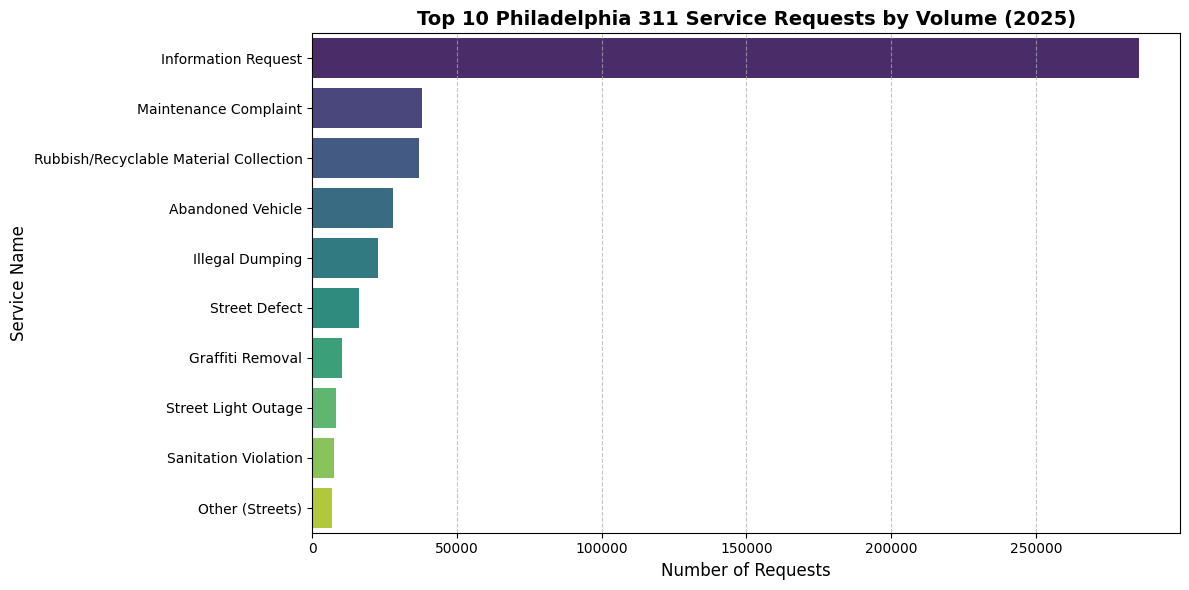

In [ ]:
# Top 10 Service Requests by Volume
import matplotlib.pyplot as plt
import seaborn as sns

# Get top 10 service requests
top_10_services = df['service_name'].value_counts().head(10).reset_index()
top_10_services.columns = ['service_name', 'request_count']

# Create a horizontal bar chart
plt.figure(figsize=(12, 6))
sns.barplot(
    x='request_count',
    y='service_name',
    data=top_10_services,
    palette='viridis',
    hue='service_name',
    legend=False
)

plt.title('Top 10 Philadelphia 311 Service Requests by Volume (2025)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Requests', fontsize=12)
plt.ylabel('Service Name', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### What should a manager notice in this chart?

*  The most striking takeaway is that **Information Requests** account for an overwhelming majority of the 311 volume. This dwarf all other physical city complaints.
*  This chart tells managers that Philly311 functions primarily as an informational hub/directory for citizens rather than purely a system for reporting physical infrastructure or sanitation failures. Staffing and training should focus heavily on immediate information provision.

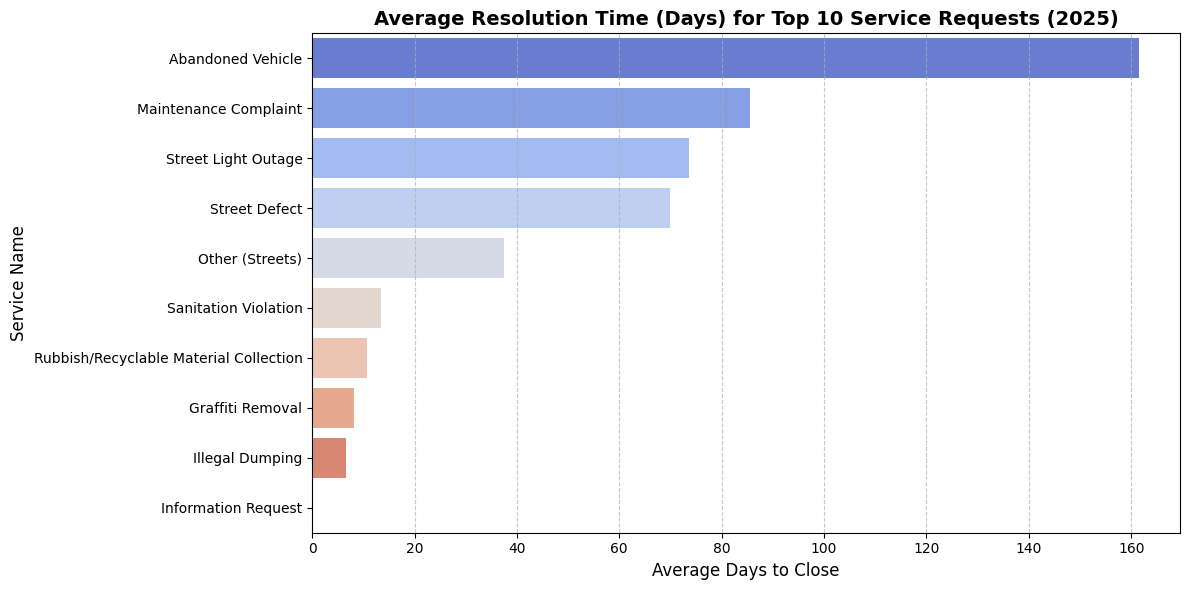

In [ ]:
# Average vs. Median Resolution Days for Top 10 Service Requests
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure we have the aggregated data ready
top_10_service_names = df['service_name'].value_counts().head(10).index
df_top_10 = df[df['service_name'].isin(top_10_service_names)]
resolution_data = df_top_10.groupby('service_name')['resolution_days'].mean().reset_index()
resolution_data = resolution_data.sort_values(by='resolution_days', ascending=False)

# Create a horizontal bar chart
plt.figure(figsize=(12, 6))
sns.barplot(
    x='resolution_days',
    y='service_name',
    data=resolution_data,
    palette='coolwarm',
    hue='service_name',
    legend=False
)

plt.title('Average Resolution Time (Days) for Top 10 Service Requests (2025)', fontsize=14, fontweight='bold')
plt.xlabel('Average Days to Close', fontsize=12)
plt.ylabel('Service Name', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### What should a manager notice in this chart?

Managers should notice the wide disparity in resolution times between different request types. While some common issues are resolved quickly (often in less than 2 days), others can linger for a week or more on average. These slower service categories represent potential bottlenecks where additional resources or process modifications could yield the biggest improvements in public satisfaction


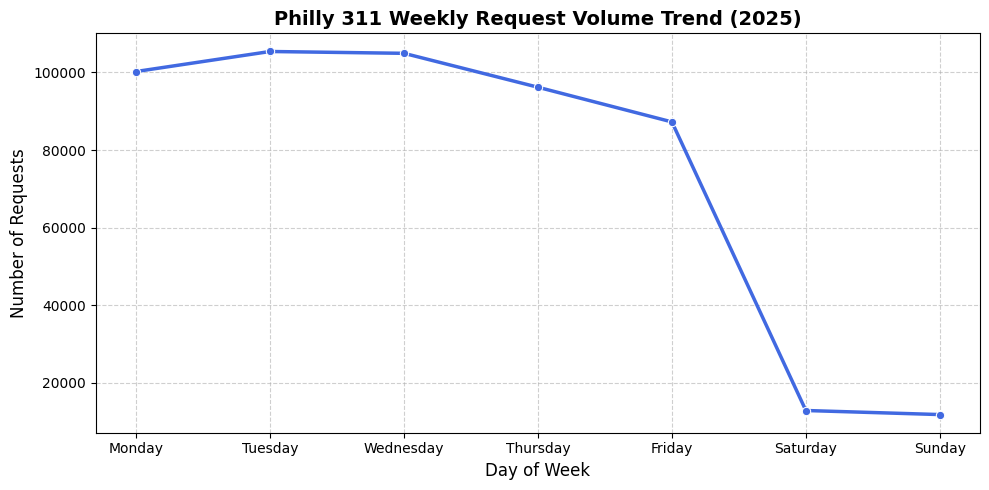

In [ ]:
# Calculate request volume by day of the week in chronological order
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekly_trend = df['request_day_of_week'].value_counts().reindex(day_order).reset_index()
weekly_trend.columns = ['Day of Week', 'Request Count']

plt.figure(figsize=(10, 5))
sns.lineplot(
    x='Day of Week',
    y='Request Count',
    data=weekly_trend,
    marker='o',
    linewidth=2.5,
    color='royalblue'
)

plt.title('Philly 311 Weekly Request Volume Trend (2025)', fontsize=14, fontweight='bold')
plt.xlabel('Day of Week', fontsize=12)
plt.ylabel('Number of Requests', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### What should a manager notice in this line chart?

* **Weekday Peak vs. Weekend Drop:** There is an extremely steep drop-off during the weekend. Requests hover between **3,600 and 5,700** on weekdays but plummet to **under 500** on Saturdays and Sundays. This indicates that 311 request submissions are heavily driven by business-day activities or live agents assisting callers during standard working hours.
* **Thursday Spike:** Thursday is the single busiest day of the week with **5,692 requests**, while Monday has the lowest weekday volume (**3,677 requests**). City managers can use this weekly curve to optimize staffing levels at the Philly311 Contact Center, ensuring peak coverage on mid-to-late weekdays (Wednesday through Friday) when the volume is highest.

# 9. Look Deeper

Good exploratory analysis often raises another question.

After seeing your initial results:

**What surprised you or made you curious?**  
I was surprised how skewed the data was.

**What additional question did that create?**  
 What information is being requested ?


In [ ]:
# Filter dataset to only include 'Information Request' cases
info_requests = df[df['service_name'] == 'Information Request']

# Analyze which agencies handle these information requests
info_by_agency = info_requests['agency_responsible'].value_counts().reset_index()
info_by_agency.columns = ['agency_responsible', 'request_count']

print("=== Top Agencies Handling Information Requests ===")
display(info_by_agency.head(10))

# Sample some of the status notes to understand the nature of the information requested
print("\n=== Sample Status Notes for Information Requests ===")
sample_notes = info_requests['status_notes'].dropna().head(10)
for i, note in enumerate(sample_notes, 1):
    print(f"{i}. {note}")

=== Top Agencies Handling Information Requests ===


,agency_responsible,request_count
0,Philly311 Contact Center,285402
1,License & Inspections,22
2,Streets Department,14
3,First Judicial District/Courts,4
4,Parks & Recreation,4
5,Office of the Inspector General,3
6,Office of Homeless Services - OHS,2
7,Department of Human Services- DHS,2
8,District Attorney's Office,2
9,Police Department,2



=== Sample Status Notes for Information Requests ===
1. Question Answered
2. Question Answered
3. Question Answered
4. Question Answered
5. Question Answered
6. Question Answered
7. Question Answered
8. Question Answered
9. Question Answered
10. Question Answered


### What did you learn?

By filtering down to 'Information Request' entries, we found which specific agencies receive the bulk of these information-seeking calls and saw sample notes detailing exactly what residents are asking about. This shows that many citizens use the 311 system not just to file complaints, but as an informational directory to navigate city services.

# 10. Managerial Summary

Imagine that the city manager will **not read your Python code**.

Summarize what management should know from your analysis.

## Our Most Important Findings

**1. Finding:**  
Almost all questions are being asked and answered y Philly311 conctact center.

**2. Finding:**  
Abandonded vehicles take the longest to resolve.

**3. Finding:**  
Most entries are Information request the platform is heavily used as an informational directory rather than just a complaint ticketing system.

**4. Finding (optional):**  
TYPE HERE

**5. Finding (optional):**  
TYPE HERE

## Recommendation / Next Question

Based on the evidence, identify **one reasonable action, area to investigate further, or question management should consider.**

TYPE HERE

### Be careful with your claims

Your analysis may identify patterns and relationships. Do not claim that one factor **caused** another unless the data and analysis actually support that conclusion.


# 11. Prepare Your 3–4 Minute Managerial Briefing

Both partners should participate.

Your audience is a **managerial team — not Python programmers**.

Use **2–3 of your strongest visualizations** and explain:

1. **What question did you investigate?**
2. **What did you discover?**
3. **What evidence supports your findings?**
4. **Why should management care?**
5. **What should management investigate or consider next?**

### Do NOT spend presentation time explaining:

- `pandas`
- DataFrames
- `groupby()`
- Python syntax
- How long your code took to debug

Those belong in the notebook. The presentation is about **what the data means**.


# 12. Final Submission Check

Before submitting:

- [ ] Both partner names are included.
- [ ] Our managerial question is clear.
- [ ] We completed at least 3 meaningful data-quality checks.
- [ ] We used at least 2 useful filters/transformations.
- [ ] We completed at least 3 meaningful groupby/aggregation analyses.
- [ ] We created at least 3 useful visualizations.
- [ ] We interpreted our results in our own words.
- [ ] Our Managerial Summary is complete.
- [ ] Both partners can explain the major Python code used.
- [ ] We restarted and ran the notebook from top to bottom without errors.
- [ ] We completed the 3–4 minute recorded managerial briefing.

## Submit to Blackboard

Submit **one completed notebook per team** and **one recorded managerial briefing per team**.
